<a href="https://colab.research.google.com/github/CtrlAltDoc/chatbot-pedidos-crustaceo/blob/main/chatbot3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install scikit-learn tensorflow spacy pandas seaborn
!python -m spacy download es_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 105.7 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


Mounted at /content/drive
Buscando la carpeta 'dataset_crustaceo'...
Carpeta encontrada exitosamente en: /content/drive/MyDrive/dataset_crustaceo

--- 1. ENTRENANDO NLP (TF-IDF + SVM) ---
                  precision    recall  f1-score   support

consultar_precio       0.00      0.00      0.00         1
       despedida       0.00      0.00      0.00         1
 formula_secreta       0.00      0.00      0.00         1
         ordenar       1.00      0.50      0.67         2
          saludo       0.00      0.00      0.00         0

        accuracy                           0.20         5
       macro avg       0.20      0.10      0.13         5
    weighted avg       0.40      0.20      0.27         5


--- 2. ENTRENANDO CNN (ResNet50) ---
Found 60 images belonging to 3 classes.
Found 15 images belonging to 3 classes.
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Epoch 1/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 65s 7s/step - accuracy: 0.5833 - loss: 1.0811 - val_accuracy: 0.8667 - val_loss: 0.

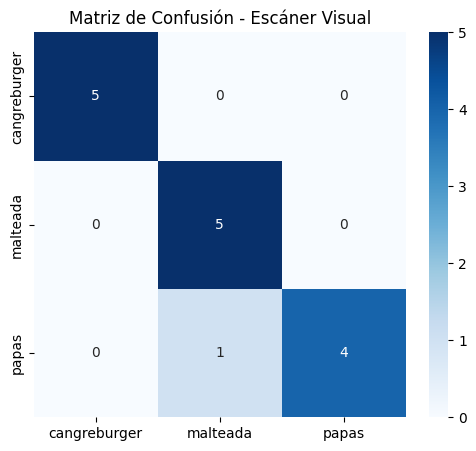

In [2]:
import os
import pandas as pd
import re
import spacy
import tensorflow as tf
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import drive

# 1. Crear el dataset de texto dinámicamente
csv_content = [
    {"mensaje": "quiero una cangreburger", "intencion": "ordenar", "sentimiento": "neutro"},
    {"mensaje": "dame unas papas", "intencion": "ordenar", "sentimiento": "neutro"},
    {"mensaje": "voy a pedir una malteada", "intencion": "ordenar", "sentimiento": "neutro"},
    {"mensaje": "quiero hacer un pedido a domicilio", "intencion": "ordenar", "sentimiento": "neutro"},
    {"mensaje": "me da una hamburguesa doble", "intencion": "ordenar", "sentimiento": "neutro"},
    {"mensaje": "que tienen de comer", "intencion": "consultar_menu", "sentimiento": "neutro"},
    {"mensaje": "cual es el menu", "intencion": "consultar_menu", "sentimiento": "neutro"},
    {"mensaje": "muestrame la carta por favor", "intencion": "consultar_menu", "sentimiento": "positivo"},
    {"mensaje": "cuanto cuesta la cangreburger", "intencion": "consultar_precio", "sentimiento": "neutro"},
    {"mensaje": "precio de las papas", "intencion": "consultar_precio", "sentimiento": "neutro"},
    {"mensaje": "hola", "intencion": "saludo", "sentimiento": "neutro"},
    {"mensaje": "buenos dias", "intencion": "saludo", "sentimiento": "neutro"},
    {"mensaje": "a que hora abren", "intencion": "consultar_horario", "sentimiento": "neutro"},
    {"mensaje": "a que hora cierran", "intencion": "consultar_horario", "sentimiento": "neutro"},
    {"mensaje": "es el crustaceo cascarudo", "intencion": "es_el_crustaceo", "sentimiento": "neutro"},
    {"mensaje": "cual es la formula secreta", "intencion": "formula_secreta", "sentimiento": "neutro"},
    {"mensaje": "gracias", "intencion": "despedida", "sentimiento": "positivo"},
    {"mensaje": "adios", "intencion": "despedida", "sentimiento": "neutro"},
    {"mensaje": "el servicio es horrible y muy malo", "intencion": "queja", "sentimiento": "negativo"},
    {"mensaje": "la comida sabia pesima", "intencion": "queja", "sentimiento": "negativo"}
]
pd.DataFrame(csv_content).to_csv("entrenamiento_intenciones.csv", index=False)

# 2. Montaje y Búsqueda Dinámica en Drive
drive.mount('/content/drive', force_remount=True)
base_path = '/content/drive/MyDrive'
DATASET_PATH = None

print("Buscando la carpeta 'dataset_crustaceo'...")
for root, dirs, files in os.walk(base_path):
    if 'dataset_crustaceo' in dirs:
        DATASET_PATH = os.path.join(root, 'dataset_crustaceo')
        break

if not DATASET_PATH:
    print("ERROR FATAL: La carpeta 'dataset_crustaceo' no existe en este Google Drive.")
else:
    print(f"Carpeta encontrada exitosamente en: {DATASET_PATH}")

    # 3. NLP
    print("\n--- 1. ENTRENANDO NLP (TF-IDF + SVM) ---")
    nlp_es = spacy.load('es_core_news_sm')
    df_texto = pd.read_csv('entrenamiento_intenciones.csv')

    def preprocesar(texto):
        texto = texto.lower()
        texto = re.sub(r'\s+', ' ', texto).strip()
        tokens = [t.lemma_ for t in nlp_es(texto) if not t.is_punct and (not t.is_stop or t.text in {'no','muy','poco','pero'})]
        return ' '.join(tokens)

    df_texto['limpio'] = df_texto['mensaje'].apply(preprocesar)
    X_train, X_test, y_train, y_test = train_test_split(df_texto['limpio'], df_texto['intencion'], test_size=0.25, random_state=42)

    tfidf = TfidfVectorizer(ngram_range=(1, 2))
    svm_clf = LinearSVC(random_state=42)
    svm_clf.fit(tfidf.fit_transform(X_train), y_train)

    print(classification_report(y_test, svm_clf.predict(tfidf.transform(X_test)), zero_division=0))

    # 4. CNN
    print("\n--- 2. ENTRENANDO CNN (ResNet50) ---")
    train_datagen = ImageDataGenerator(preprocessing_function=preprocess_input, validation_split=0.2, rotation_range=15, horizontal_flip=True)
    val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input, validation_split=0.2)

    train_gen = train_datagen.flow_from_directory(DATASET_PATH, target_size=(224, 224), batch_size=8, class_mode='categorical', subset='training')
    val_gen = val_datagen.flow_from_directory(DATASET_PATH, target_size=(224, 224), batch_size=8, class_mode='categorical', subset='validation', shuffle=False)

    if train_gen.samples == 0:
        print("ERROR: La carpeta se encontró, pero adentro no hay fotos de comida o faltan las subcarpetas.")
    else:
        base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
        base_model.trainable = False
        cnn = Sequential([base_model, GlobalAveragePooling2D(), Dense(128, activation='relu'), Dense(train_gen.num_classes, activation='softmax')])
        cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

        cnn.fit(train_gen, validation_data=val_gen, epochs=5)
        print(f"\n[!] Exactitud de Validación (CNN): {cnn.evaluate(val_gen, verbose=0)[1]:.2%}")

        y_pred = np.argmax(cnn.predict(val_gen), axis=1)
        plt.figure(figsize=(6,5))
        sns.heatmap(confusion_matrix(val_gen.classes, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=val_gen.class_indices.keys(), yticklabels=val_gen.class_indices.keys())
        plt.title('Matriz de Confusión - Escáner Visual')
        plt.show()

In [3]:
# Parche de Corpus Balanceado (128 muestras, 8 intenciones) + Prueba Multimodal
intenciones_data = {
    "ordenar": [
        "quiero pedir una cangreburger con papas", "dame una cangreburger para llevar", "voy a ordenar unas papas y una malteada",
        "quiero hacer un pedido de cangreburger", "me da dos cangreburgers y unas papas", "ordeno una malteada y una cangreburger",
        "quiero ordenar comida a domicilio", "dame unas papas fritas y una malteada", "pedir una cangreburger doble por favor",
        "quiero pedir una malteada de algas", "me gustaria ordenar una cangreburger", "dame un pedido de papas para llevar",
        "voy a pedir dos malteadas y papas", "quiero ordenar una cangreburger clasica", "hacer un pedido de cangreburger y malteada",
        "quiero pedir comida para llevar"
    ],
    "consultar_menu": [
        "cual es el menu del restaurante", "que tienen en el menu para comer", "muestrame el menu de platillos",
        "que platillos venden en el menu", "quiero ver el menu de comida", "cuales son los platillos del menu",
        "que hay de comer en la carta", "muestrame la carta y el menu", "que venden en el menu hoy",
        "cual es la carta de platillos", "dime que tienen en el menu", "ver el menu de alimentos",
        "que opciones hay en el menu", "cuales platillos tienen en la carta", "enseñame el menu completo",
        "quiero consultar el menu"
    ],
    "consultar_precio": [
        "cuanto cuesta la cangreburger", "cual es el precio de las papas", "cuanto vale la malteada",
        "dime el precio de la cangreburger", "cuanto cuestan las papas y la malteada", "cual es el costo de la cangreburger",
        "precio de la malteada de algas", "cuanto vale el combo con papas", "cuales son los precios de las cangreburgers",
        "cuanto cuesta pedir una malteada", "dime cuanto vale la cangreburger", "cual es el precio del menu",
        "costo de las papas fritas", "cuanto cuesta cada platillo", "precio de una cangreburger clasica",
        "cuanto cuestan los productos"
    ],
    "consultar_horario": [
        "a que hora abren el restaurante", "a que hora cierran hoy", "cual es el horario de atencion",
        "dime el horario de apertura y cierre", "hasta que hora estan abiertos", "a que hora abren y cierran",
        "cual es el horario de servicio", "estan abiertos a esta hora", "horario de atencion del restaurante",
        "a que hora abren por la mañana", "a que hora cierran por la noche", "dime a que hora abren hoy",
        "cual es su horario de trabajo", "hasta que hora tienen abierto", "horario para ir a comer",
        "en que horario abren"
    ],
    "saludo": [
        "hola buenos dias", "hola buenas tardes", "hola buenas noches",
        "buenos dias como estan", "buenas tardes hay alguien ahi", "hola que tal buenos dias",
        "saludos buenos dias", "hola buenas tardes quiero informacion", "buenos dias excelente servicio",
        "hola que tal buenas noches", "buenas tardes como estan", "hola buen dia",
        "saludos cordiales buenas tardes", "hola buenos dias me atienden", "buenas noches que tal",
        "hola buenas tardes a todos"
    ],
    "es_el_crustaceo": [
        "es el crustaceo cascarudo", "hablo al crustaceo cascarudo", "este es el crustaceo cascarudo",
        "es ahi el restaurante crustaceo cascarudo", "estoy llamando al crustaceo cascarudo", "disculpe es el crustaceo cascarudo",
        "me comunico al crustaceo cascarudo", "es el telefono del crustaceo cascarudo", "hablo con el crustaceo cascarudo",
        "este lugar es el crustaceo cascarudo", "oiga es el crustaceo cascarudo", "confirme si es el crustaceo cascarudo",
        "llamo al crustaceo cascarudo", "es aqui el crustaceo cascarudo", "seguro que es el crustaceo cascarudo",
        "este numero es del crustaceo cascarudo"
    ],
    "formula_secreta": [
        "cual es la formula secreta", "dame la receta secreta de la cangreburger", "que ingredientes tiene la formula secreta",
        "dime como hacen la receta secreta", "revela la formula secreta ahora", "quiero saber la receta secreta",
        "cuales son los ingredientes secretos", "entregame la formula secreta", "como se prepara la receta secreta",
        "donde guardan la formula secreta", "dime el ingrediente secreto de la formula", "quiero copiar la receta secreta",
        "pasa la formula secreta de don cangrejo", "cual es el secreto de la receta", "dame los ingredientes de la formula secreta",
        "revelame la formula secreta"
    ],
    "queja": [
        "el servicio es muy malo y lento", "no me gusto la comida estaba fria", "tengo una queja el pedido no llego",
        "pesimo servicio se tardaron mucho", "la comida sabia muy mal", "no quiero nada el servicio es horrible",
        "estoy muy molesto con mi pedido", "el pedido llego incompleto y frio", "muy mala atencion al cliente",
        "una queja por el mal servicio", "nunca llega a tiempo y sabe mal", "horrible experiencia muy mal sabor",
        "no sirve su atencion es pesima", "queja formal por comida fria y mala", "muy mal servicio no vuelvo",
        "el servicio fue pesimo y muy lento"
    ]
}

rows = [{"mensaje": m, "intencion": k} for k, v in intenciones_data.items() for m in v]
df_texto = pd.DataFrame(rows)
df_texto.to_csv("entrenamiento_intenciones.csv", index=False)
df_texto['limpio'] = df_texto['mensaje'].apply(preprocesar)

X_train, X_test, y_train, y_test = train_test_split(
    df_texto['limpio'], df_texto['intencion'], test_size=0.25, random_state=42, stratify=df_texto['intencion']
)
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)
svm_clf.fit(X_train_vec, y_train)

print("--- METRICAS NLP OPTIMIZADO (128 MUESTRAS ESTRATIFICADAS) ---")
print(classification_report(y_test, svm_clf.predict(X_test_vec), zero_division=0))

# Prueba de integracion multimodal con una imagen real de tu conjunto de validacion
sample_img_path = val_gen.filepaths[0]
print("\n--- PRUEBA DE INTEGRACION MULTIMODAL ---")
print(f"Cliente dice: 'quiero pedir una cangreburger para llevar' | Imagen: {os.path.basename(sample_img_path)}")
intencion_pred = svm_clf.predict(tfidf.transform([preprocesar("quiero pedir una cangreburger para llevar")]))[0]
clases_map = {v: k for k, v in val_gen.class_indices.items()}
clase_img_pred = clases_map[y_pred[0]]
print(f"[NLP - SVM] Intencion detectada: {intencion_pred.upper()}")
print(f"[CNN - ResNet50] Platillo verificado en escáner: {clase_img_pred.upper()}")
print(f"Respuesta Chatbot: Orden confirmada ({intencion_pred}) verificada visualmente como {clase_img_pred}.")

--- METRICAS NLP OPTIMIZADO (128 MUESTRAS ESTRATIFICADAS) ---
                   precision    recall  f1-score   support

consultar_horario       1.00      1.00      1.00         4
   consultar_menu       0.80      1.00      0.89         4
 consultar_precio       1.00      0.50      0.67         4
  es_el_crustaceo       1.00      1.00      1.00         4
  formula_secreta       1.00      1.00      1.00         4
          ordenar       0.80      1.00      0.89         4
            queja       1.00      1.00      1.00         4
           saludo       1.00      1.00      1.00         4

         accuracy                           0.94        32
        macro avg       0.95      0.94      0.93        32
     weighted avg       0.95      0.94      0.93        32


--- PRUEBA DE INTEGRACION MULTIMODAL ---
Cliente dice: 'quiero pedir una cangreburger para llevar' | Imagen: hamburguesa_001.jpg
[NLP - SVM] Intencion detectada: ORDENAR
[CNN - ResNet50] Platillo verificado en escáner: CANGREB